# 03.2 · 因子中性化（行业 / 市值）

> 上一节我们把反转因子处理成了"干净"的数值。但它的预测力可能**夹带了行业和市值的暴露**——比如某些行业天然超跌、小盘股天然波动大。
> 本节学会：**用截面回归剔除这些已知风险，提取因子的"纯 alpha"（残差）**。

## 一、为什么要中性化

考虑反转因子：
- 某段时间金融、地产板块整体超跌，反转因子在这些行业天然偏高 → 因子的"预测力"其实是在赌行业；
- 小盘股波动大，反转因子也更极端 → 可能只是市值效应。

**中性化（Neutralization）= 把因子中能被行业、市值等已知风险解释的部分剔除，剩下的残差才是真正的选股 alpha。**

意义：
1. **评估因子的纯预测力**：去掉"靠行业/市值 beta"的部分；
2. **组合层面控风险**：避免组合在某个行业或市值上过度集中（模块 5 会用到）。

## 二、原理：截面回归取残差

在每个交易日的截面上做线性回归：

$$ y = X\beta + \varepsilon $$

- $y$：该截面所有股票的因子值；
- $X$：要剔除的风险变量（行业哑变量、log 市值）；
- $\beta$：因子在这些风险上的暴露；
- $\varepsilon$：**残差，即无法被风险解释的部分 = 中性化后的因子**。

最小二乘解：$\hat\beta = (X^\top X)^{-1}X^\top y$，残差 $\hat\varepsilon = y - X\hat\beta$。

## 三、准备数据：因子、行业、市值

In [1]:
import sys, numpy as np, pandas as pd
import matplotlib.pyplot as plt
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
import config
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = D.list_instruments(D.instruments('all'), as_list=True, freq='day')

# 后复权收盘价 -> 反转因子（沿用上节，这里直接算原始因子）
close = D.features(codes, ['$close'], freq='day')['$close'].unstack('instrument')
rev20 = -close.pct_change(20)

# 行业映射（qlib 代码大写）
pool = pd.read_csv(config.INDEX_UNIVERSE_DIR / '000300_sh.csv')
pool['upper'] = pool['qlib_code'].str.upper()
ind_map = dict(zip(pool['upper'], pool['industry']))

# 市值（总市值），取 log
mkt = D.features(codes, ['$mkt_cap_ard'], freq='day')['$mkt_cap_ard'].unstack('instrument')
logmkt = np.log(mkt)
print('因子:', rev20.shape, ' 市值:', logmkt.shape, ' 行业数:', pool.industry.nunique())

[25472:MainThread](2026-10-29 19:36:24,590) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[25472:MainThread](2026-10-29 19:36:26,056) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[25472:MainThread](2026-10-29 19:36:26,057) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


因子: (2139, 300)  市值: (2139, 300)  行业数: 11


## 四、截面中性化函数

下面写一个通用函数：对每个截面，用风险矩阵 $X$ 回归因子，返回残差。
- 加入截距项（一列 1）；
- 行业用 one-hot 哑变量（`drop_first=True` 避免与截距完全共线）；
- 用 `np.linalg.lstsq` 做最小二乘（数值稳定）。

In [2]:
def cross_residual(y, X):
    """单截面回归，返回残差。y: Series, X: DataFrame。"""
    valid = y.notna()
    if X is not None:
        valid = valid & X.notna().all(axis=1)
    yv = y[valid]
    Xv = X.loc[valid] if X is not None else pd.DataFrame(index=yv.index)
    Xmat = np.column_stack([np.ones(len(Xv)), Xv.values.astype(float)])
    beta, *_ = np.linalg.lstsq(Xmat, yv.values, rcond=None)
    resid = yv.values - Xmat @ beta
    return pd.Series(resid, index=yv.index)

def neutralize(factor, ind_map=None, logmkt=None, by_industry=True, by_size=True):
    out = pd.DataFrame(index=factor.index, columns=factor.columns, dtype=float)
    for dt, y in factor.iterrows():
        cols = []
        if by_industry and ind_map is not None:
            ind = pd.Series([ind_map.get(c, '其他') for c in factor.columns],
                            index=factor.columns)
            cols.append(pd.get_dummies(ind, drop_first=True))
        if by_size and logmkt is not None:
            cols.append(logmkt.loc[dt].rename('logmkt').to_frame())
        X = pd.concat(cols, axis=1) if cols else None
        r = cross_residual(y, X)
        out.loc[dt, r.index] = r.values
    return out

## 五、行业中性化

只放行业哑变量，剔除行业影响。验证：中性化后**每个行业的因子均值都应接近 0**。

In [3]:
rev_ind = neutralize(rev20, ind_map=ind_map, by_industry=True, by_size=False)

# 验证：中性化前后各行业因子均值
def industry_mean(factor):
    s = factor.iloc[-1]
    g = pd.DataFrame({'v': s})
    g['ind'] = [ind_map.get(c, '其他') for c in g.index]
    return g.groupby('ind')['v'].mean()

cmp = pd.DataFrame({'中性化前': industry_mean(rev20), '中性化后': industry_mean(rev_ind)})
print(cmp.round(4))
print('\n中性化后行业均值绝对值最大:', cmp['中性化后'].abs().max().round(6))

        中性化前  中性化后
ind               
信息技术  0.2166   0.0
公用事业 -0.0794  -0.0
医疗保健 -0.0145  -0.0
可选消费  0.0198  -0.0
工业    0.0404  -0.0
房地产   0.0446  -0.0
日常消费 -0.0224   0.0
材料    0.1237   0.0
能源   -0.0399   0.0
通讯服务 -0.0193  -0.0
金融    0.0104  -0.0

中性化后行业均值绝对值最大: 0.0


## 六、市值中性化

只放 log(市值)，剔除市值影响。验证：中性化后因子与 log 市值的**相关性应接近 0**。

中性化前 因子与log市值相关性: -0.1558
中性化后 因子与log市值相关性: -0.0000


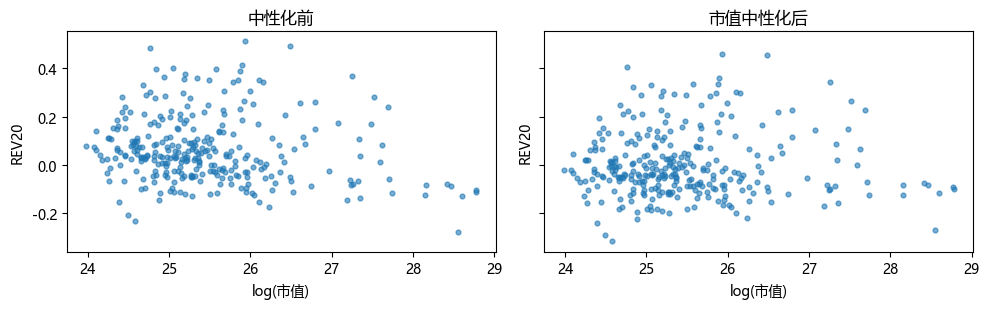

In [4]:
rev_size = neutralize(rev20, logmkt=logmkt, by_industry=False, by_size=True)

def corr_with_size(factor):
    s, m = factor.iloc[-1], logmkt.iloc[-1]
    return s.corr(m)
print('中性化前 因子与log市值相关性: %.4f' % corr_with_size(rev20))
print('中性化后 因子与log市值相关性: %.4f' % corr_with_size(rev_size))

# 散点图直观对比
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, (t, f) in zip(axes, [('中性化前', rev20), ('市值中性化后', rev_size)]):
    s, m = f.iloc[-1], logmkt.iloc[-1]
    ax.scatter(m, s, s=12, alpha=.6)
    ax.set_xlabel('log(市值)'); ax.set_ylabel('REV20'); ax.set_title(t)
plt.tight_layout(); plt.show()

## 七、行业 + 市值联合中性化

实战中通常**一次性同时剔除行业和市值**（也可加入更多 Barra 风格因子，模块 5 会讲）。

联合中性化后：
  行业均值绝对值最大: 0.0
  与log市值相关性: 0.0000


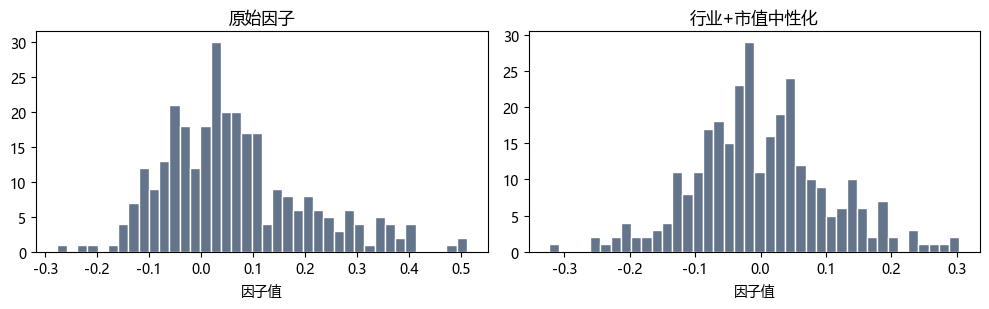

In [5]:
rev_neut = neutralize(rev20, ind_map=ind_map, logmkt=logmkt,
                       by_industry=True, by_size=True)
print('联合中性化后：')
print('  行业均值绝对值最大:', pd.Series(industry_mean(rev_neut)).abs().max().round(6))
print('  与log市值相关性: %.4f' % rev_neut.iloc[-1].corr(logmkt.iloc[-1]))

# 中性化前后分布对比
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
for ax, (t, f) in zip(axes, [('原始因子', rev20), ('行业+市值中性化', rev_neut)]):
    ax.hist(f.iloc[-1].dropna(), bins=40, color='#64748b', edgecolor='white')
    ax.set_title(t); ax.set_xlabel('因子值')
plt.tight_layout(); plt.show()

## 八、小结与面试要点

- 中性化 = 用**截面回归**剔除行业、市值等已知风险，**残差才是纯 alpha**。
- 行业中性化用行业哑变量；市值中性化用 log(市值)；实战常联合，甚至加入更多 Barra 风格因子。
- 验证标准：中性化后各行业因子均值≈0、因子与市值相关性≈0。
- 注意：中性化也在**每个截面独立**进行，不能用未来信息。

**面试高频：**
- 为什么要做中性化？不做会怎样？（答：因子收益可能只是行业/市值 beta，不是纯 alpha；组合会有隐性风险集中）
- 中性化的数学原理？（答：线性回归取残差，残差与风险因子正交）
- 行业哑变量为什么要 drop_first？（答：避免与截距项完全共线性，即"哑变量陷阱"）

## 动手练习
1. 对比反转因子在"仅行业中性化"和"联合中性化"后的差异；
2. 思考：中性化后因子的 IC 一定上升吗？（提示：不一定，可能下降，因为剔除了有预测力的风格暴露）
3. 若要再加入"波动率"风格，X 矩阵该怎么改？

---
下一节 **03.3 因子评估：IC / RankIC / IR / IC 衰减**。